In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zom8ie99/maize-seed")

print("Path to dataset files:", path)

100%|██████████| 11.0G/11.0G [08:40<00:00, 22.6MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/zom8ie99/maize-seed/versions/1


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("emmarex/plantdisease")

print("Path to dataset files:", path)

100%|██████████| 658M/658M [00:30<00:00, 22.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/emmarex/plantdisease/versions/1


In [4]:
!pip install fiftyone --quiet

import fiftyone.zoo as foz
import fiftyone.types as fot

dataset = foz.load_zoo_dataset("coco-2017", split="validation")
dataset.export(export_dir="not_corn", dataset_type=fot.ImageDirectory)

INFO:fiftyone.zoo.datasets:Downloading split 'validation' to '/root/fiftyone/coco-2017/validation' if necessary


Found annotations at '/root/fiftyone/coco-2017/raw/instances_val2017.json'


INFO:fiftyone.utils.coco:Found annotations at '/root/fiftyone/coco-2017/raw/instances_val2017.json'


Found 20 (< 5000) downloaded images; must download full image zip


INFO:fiftyone.utils.coco:Found 20 (< 5000) downloaded images; must download full image zip


INFO:fiftyone.utils.coco:Downloading images to '/root/fiftyone/coco-2017/tmp-download/val2017.zip'


... (13 outputs left out)

Dataset 'coco-2017-validation' created


INFO:fiftyone.zoo.datasets:Dataset 'coco-2017-validation' created


 100% |███████████████| 5000/5000 [15.5s elapsed, 0s remaining, 384.4 samples/s]      


INFO:eta.core.utils: 100% |███████████████| 5000/5000 [15.5s elapsed, 0s remaining, 384.4 samples/s]      


In [5]:
import os
import shutil
from pathlib import Path
from glob import glob

# Paths
corn_root = "/root/.cache/kagglehub/datasets/zom8ie99/maize-seed/versions/1"  # <-- change this to your corn folder
output_root = "/content/corn_binary_dataset"

corn_out = os.path.join(output_root, "corn")
notcorn_out = os.path.join(output_root, "not_corn")

os.makedirs(corn_out, exist_ok=True)
os.makedirs(notcorn_out, exist_ok=True)

corn_extensions = (".JPG", ".jpeg", ".png")

corn_images = []
for ext in corn_extensions:
    corn_images.extend(glob(os.path.join(corn_root, "**", f"*{ext}"), recursive=True))

print(f"Found {len(corn_images)} corn images")

for i, img_path in enumerate(corn_images):
    filename = f"corn_{i:05d}" + Path(img_path).suffix
    shutil.copy(img_path, os.path.join(corn_out, filename))


Found 6000 corn images


In [6]:
import os
import shutil
from glob import glob
from pathlib import Path

# --- Paths ---
plantvillage_root = "/root/.cache/kagglehub/datasets/emmarex/plantdisease/versions/1"
coco_root = "/root/fiftyone/coco-2017/validation/data"
not_corn_out = "/content/corn_binary_dataset/not_corn"

os.makedirs(not_corn_out, exist_ok=True)

# --- Supported image extensions ---
img_exts = (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG")

# --- Helper: copy all images recursively ---
def copy_all_images(src_root, dst_root, prefix):
    all_imgs = []
    for ext in img_exts:
        all_imgs.extend(glob(os.path.join(src_root, "**", f"*{ext}"), recursive=True))
    print(f"[{prefix}] Found {len(all_imgs)} images")

    for i, img_path in enumerate(all_imgs):
        fname = f"{prefix}_{i:06d}{Path(img_path).suffix.lower()}"
        dst_path = os.path.join(dst_root, fname)
        try:
            shutil.copy(img_path, dst_path)
        except Exception as e:
            print(f"Skip {img_path}: {e}")

# --- 1️⃣ Copy from PlantVillage ---
copy_all_images(plantvillage_root, not_corn_out, prefix="plantvillage")

# --- 2️⃣ Copy from COCO ---
copy_all_images(coco_root, not_corn_out, prefix="coco")

print(f"\n✅ All non-corn images collected into: {not_corn_out}")
print(f"Total images: {len(os.listdir(not_corn_out))}")


[plantvillage] Found 41276 images
[coco] Found 5000 images

✅ All non-corn images collected into: /content/corn_binary_dataset/not_corn
Total images: 46276


In [12]:
import os
from glob import glob

# --- Paths ---
corn_dir = "/content/corn_binary_dataset/corn"
notcorn_dir = "/content/corn_binary_dataset/not_corn"

# --- Supported image extensions ---
img_exts = (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG")

# --- Helper function ---
def count_images(folder):
    count = 0
    missing_files = []
    for ext in img_exts:
        files = glob(os.path.join(folder, f"*{ext}"))
        count += len(files)
    return count

# --- Count images ---
corn_count = count_images(corn_dir)
notcorn_count = count_images(notcorn_dir)

# --- Print summary ---
print("📊 DATASET VALIDATION SUMMARY")
print("-" * 40)
print(f"🌽 Corn images:     {corn_count:,}")
print(f"🚫 Not-corn images: {notcorn_count:,}")
print("-" * 40)

if corn_count == 0:
    print("⚠️ No corn images found! Check your corn path.")
if notcorn_count == 0:
    print("⚠️ No not-corn images found! Check your non-corn path.")
elif abs(corn_count - notcorn_count) / max(corn_count, notcorn_count) > 0.2:
    print("⚠️ Warning: Dataset imbalance > 20%. Consider balancing before training.")
else:
    print("✅ Dataset looks balanced and ready for training!")


📊 DATASET VALIDATION SUMMARY
----------------------------------------
🌽 Corn images:     18,168
🚫 Not-corn images: 46,276
----------------------------------------
⚠️ Warning: Dataset imbalance > 20%. Consider balancing before training.


In [11]:
import tensorflow as tf
import os
import numpy as np
from glob import glob
from tqdm import tqdm
from pathlib import Path

corn_dir = "/content/corn_binary_dataset/corn"
target_count = 50000
save_dir = corn_dir

# Collect images
img_exts = (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG")
corn_images = []
for ext in img_exts:
    corn_images.extend(glob(os.path.join(corn_dir, f"*{ext}")))
current_count = len(corn_images)
print(f"🌽 Found {current_count} corn images")

augment_needed = target_count - current_count
if augment_needed <= 0:
    print("✅ You already have 50k or more corn images.")
else:
    print(f"✨ Need to generate {augment_needed} more images via augmentation...")

# --- TensorFlow augmentation pipeline ---
def decode_img(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, [224, 224])
    return img

@tf.function
def augment(img):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, 0.3)
    img = tf.image.random_contrast(img, 0.7, 1.3)
    img = tf.image.random_saturation(img, 0.7, 1.3)
    img = tf.image.random_hue(img, 0.05)
    img = tf.image.random_rotation(img, 0.2) if hasattr(tf.image, 'random_rotation') else img
    img = tf.image.resize_with_crop_or_pad(img, 224, 224)
    return tf.clip_by_value(img, 0, 1)

def save_img(tensor, save_path):
    tensor = tf.image.convert_image_dtype(tensor, dtype=tf.uint8)
    img_bytes = tf.io.encode_jpeg(tensor)
    tf.io.write_file(save_path, img_bytes)

# Create dataset
dataset = tf.data.Dataset.from_tensor_slices(corn_images)
dataset = dataset.shuffle(buffer_size=current_count)
dataset = dataset.map(decode_img, num_parallel_calls=tf.data.AUTOTUNE)

# Use GPU to augment batches
batch_size = 64
dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

generated = 0
counter = 0
pbar = tqdm(total=augment_needed, desc="Augmenting corn images (GPU)")

for batch in dataset:
    aug_batch = augment(batch)
    for img in aug_batch:
        if generated >= augment_needed:
            break
        out_path = os.path.join(save_dir, f"aug_{counter:06d}.jpg")
        save_img(img, out_path)
        generated += 1
        counter += 1
        pbar.update(1)
    if generated >= augment_needed:
        break

pbar.close()
print(f"✅ Augmentation complete. Total corn images ≈ {len(glob(os.path.join(corn_dir, '*')))}")


🌽 Found 12112 corn images
✨ Need to generate 37888 more images via augmentation...


Augmenting corn images (GPU):  32%|███▏      | 12112/37888 [07:35<16:09, 26.60it/s]

✅ Augmentation complete. Total corn images ≈ 18168


In [7]:
import os
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import matplotlib.pyplot as plt

# --- Configuration ---
data_dir = "/content/corn_binary_dataset"
batch_size = 64
num_epochs = 1
lr = 1e-4
max_images_per_class = 20000
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {device}")

# --- Transforms (augmentations + normalization) ---
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# --- Load dataset ---
dataset = datasets.ImageFolder(root=data_dir, transform=train_transforms)

# --- Limit to 20k images per class ---
class_indices = {cls_idx: [] for cls_idx in range(len(dataset.classes))}
for sample in dataset.samples:
    label = sample[1]
    if len(class_indices[label]) < max_images_per_class:
        class_indices[label].append(sample)
dataset.samples = [s for v in class_indices.values() for s in v]

print(f"🌽 Loaded {len(dataset.samples)} total images (<=20k/class)")

# --- Split into train and val ---
val_ratio = 0.2
val_size = int(len(dataset) * val_ratio)
train_size = len(dataset) - val_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
val_dataset.dataset.transform = val_transforms

# --- DataLoaders ---
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True, persistent_workers=False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True, persistent_workers=False)

# --- Model ---
model = models.resnet50(pretrained=True)
for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 1) # Removed the duplicate linear layer
)
model = model.to(device)

criterion = nn.BCEWithLogitsLoss() # Changed to BCEWithLogitsLoss
optimizer = optim.Adam(model.fc.parameters(), lr=lr)
scaler = torch.cuda.amp.GradScaler()

# --- Training & Validation ---
def train_one_epoch(epoch):
    model.train()
    running_loss, correct, total = 0, 0, 0
    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{num_epochs}]")
    for inputs, labels in loop:
        inputs, labels = inputs.to(device), labels.float().unsqueeze(1).to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            outputs = model(inputs)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        preds = (torch.sigmoid(outputs) > 0.5).float() # Apply sigmoid for prediction
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        running_loss += loss.item() * inputs.size(0)
        loop.set_postfix(loss=loss.item(), acc=100 * correct / total)
    return running_loss / total, correct / total

def validate():
    model.eval()
    running_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.float().unsqueeze(1).to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            preds = (torch.sigmoid(outputs) > 0.5).float() # Apply sigmoid for prediction
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            running_loss += loss.item() * inputs.size(0)
    return running_loss / total, correct / total

# --- Main Training Loop ---
best_acc = 0
for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(epoch)
    val_loss, val_acc = validate()
    print(f"\nEpoch {epoch+1}: Train Acc={train_acc:.4f}, Val Acc={val_acc:.4f}")
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), "corn_classifier_best.pt")
        print("💾 Saved best model")

print(f"🏁 Best Validation Accuracy: {best_acc:.4f}")

✅ Using device: cuda
🌽 Loaded 38168 total images (<=20k/class)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/tmp/ipython-input-3537842765.py:74: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Epoch [1/1]:   0%|          | 0/478 [00:00<?, ?it/s]/tmp/ipython-input-3537842765.py:84: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.am


Epoch 1: Train Acc=0.9958, Val Acc=0.9995
💾 Saved best model
🏁 Best Validation Accuracy: 0.9995


Evaluating: 100%|██████████| 120/120 [02:38<00:00,  1.32s/it]
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127805 (\N{EAR OF MAIZE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


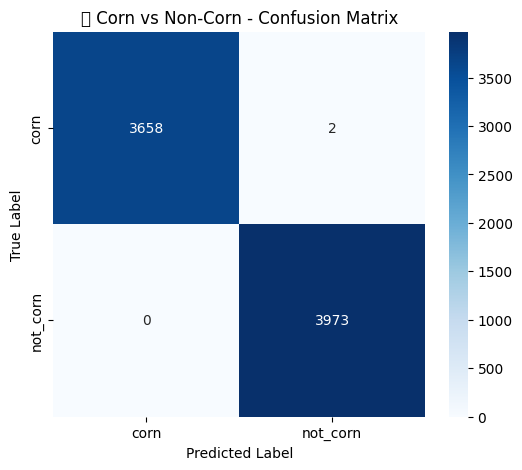

📊 Classification Report:

              precision    recall  f1-score   support

        corn       1.00      1.00      1.00      3660
    not_corn       1.00      1.00      1.00      3973

    accuracy                           1.00      7633
   macro avg       1.00      1.00      1.00      7633
weighted avg       1.00      1.00      1.00      7633



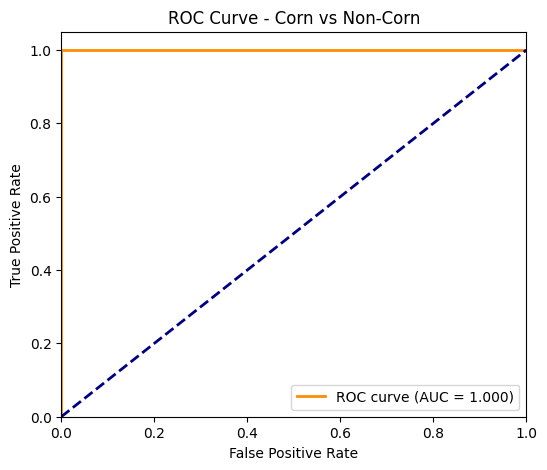

✅ Overall Validation Accuracy: 99.97%
🔹 AUC Score: 1.000


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

# --- Load best model ---
model.load_state_dict(torch.load("corn_classifier_best.pt"))
model.eval()

# --- Collect true and predicted labels ---
all_labels = []
all_preds = []
all_probs = []

with torch.no_grad():
    for inputs, labels in tqdm(val_loader, desc="Evaluating"):
        inputs, labels = inputs.to(device), labels.float().unsqueeze(1).to(device)
        outputs = model(inputs)
        probs = outputs.cpu().numpy().flatten()
        preds = (outputs > 0.5).float().cpu().numpy().flatten()
        all_labels.extend(labels.cpu().numpy().flatten())
        all_preds.extend(preds)
        all_probs.extend(probs)

all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)
class_labels = dataset.classes

# --- Confusion Matrix ---
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
plt.title("🌽 Corn vs Non-Corn - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# --- Classification Report ---
print("📊 Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_labels))

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(all_labels, all_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Corn vs Non-Corn')
plt.legend(loc="lower right")
plt.show()

# --- Summary ---
accuracy = np.mean(all_preds == all_labels)
print(f"✅ Overall Validation Accuracy: {accuracy*100:.2f}%")
print(f"🔹 AUC Score: {roc_auc:.3f}")


0.9085463285446167


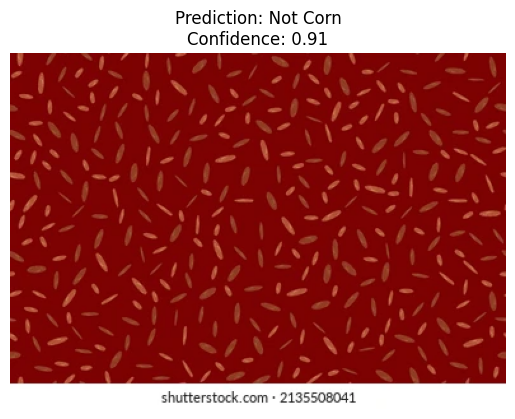

In [20]:
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

# --- Load model ---
model = models.resnet50(pretrained=False)
num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 1),
    nn.Sigmoid()
)
model.load_state_dict(torch.load("corn_classifier_best.pt", map_location=device))
model.eval()
model.to(device)

# --- Class labels ---
class_labels = ['not_corn', 'corn']  # same order as dataset

# --- Preprocess single image ---
sample_path = "/content/red-rice-seamless-grain-drawn-260nw-2135508041.webp"  # your image path
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

img = Image.open(sample_path).convert("RGB")
input_tensor = transform(img).unsqueeze(0).to(device)

# --- Predict ---
with torch.no_grad():
    prob = model(input_tensor).item()
print(prob)
pred_class = "Corn" if prob <= 0.5 else "Not Corn"

# --- Display result ---
plt.imshow(img)
plt.axis("off")
plt.title(f"Prediction: {pred_class}\nConfidence: {prob:.2f}")
plt.show()


In [ ]:
from google.colab import drive
drive.mount('/content/drive')